In [4]:
import numpy as np
from alpyne.env import AlpyneEnv
from alpyne.sim import AnyLogicSim
from gymnasium import spaces
from alpyne.data import SimStatus, SimConfiguration
from gymnasium.core import ActType, ObsType
from typing import SupportsFloat
from alpyne.typing import EngineSettingKeys
import typing
from typing import Any, SupportsFloat, Callable
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3 import SAC, PPO, DQN
import os
from stable_baselines3.common.vec_env.subproc_vec_env import SubprocVecEnv
from stable_baselines3.common.vec_env.dummy_vec_env import DummyVecEnv
from stable_baselines3.common.vec_env import VecNormalize
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.vec_env import VecMonitor
from sb3_contrib import MaskablePPO
from stable_baselines3.common.callbacks import BaseCallback
from collections import deque
import ast
import matplotlib.pyplot as plt
from alpyne.utils import next_num


In [5]:
class MyEnvironment(AlpyneEnv):
    
    def __init__(self, sim:AnyLogicSim):
        super().__init__(sim)
        self.observation_space = spaces.Box(low = 0.0, high= 1.0, shape=(27,), dtype=np.float32)
        self.action_space = spaces.Box(low=np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0]), high=np.array([10.0, 10.0, 10.0, 1.0, 1.0, 10.0]), dtype=np.float64)
        self.lastAction = None|ActType
        self.previousStatus = None|SimStatus
        self.finalProgress = None
        self.finalWasteRebar= None
        self.finalWasteForm= None
        
        # self.areaZoneList = [50,100,150,200]
        # self.numZoneList = [1,2,3,4]
        # self.numFloorList = [2,3,4,5]


        self.confs = [
            (50, 1, 2),

        ]


        self.areaZone = None
        self.numZone  = None
        self.numFloor = None
        self.cashStart = None
        self.storageCap = 2.0
        self.payPerUnit = 450
        self.removeFormC = 1
        self.removeFormBF = 14

        self.termination = None
        


        self.rng = np.random.RandomState() 


    def _get_config(self)-> SimConfiguration|None:


        #self.areaZone = self.rng.choice(self.areaZoneList)
        #self.areaZone = 50
        #self.numZone = self.rng.choice(self.numZoneList)
        #self.numZone = 1
        #self.numFloor = self.rng.choice(self.numFloorList)
        #self.numFloor = 3
    
        idx = self.rng.randint(0, len(self.confs))
        self.areaZone, self.numZone, self.numFloor = self.confs[idx]
        
        
        
        self.termination = self.areaZone*  self.numZone*  self.numFloor
        self.cashStart = int(self.areaZone * self.numZone * self.payPerUnit * 1.2)
        

        myConfig = SimConfiguration(cnfAreaZone = self.areaZone,
                                    cnfNumZone = self.numZone,
                                    cnfNumFloor = self.numFloor,
                                    cnfCashStart = self.cashStart,
                                    cnfPayPerUnit = self.payPerUnit,
                                    cnfStorageCapacity = self.storageCap,
                                    cnfRemoveFormC = self.removeFormC,
                                    cnfRemoveFormBF = self.removeFormBF)
    
        return myConfig
    

        
    def _get_obs(self, status:SimStatus) -> ObsType:


        obsCapRebar = status.observation['obsCapRebar']/10
        obsCapForm = status.observation['obsCapForm']/10
        obsCapConc = status.observation['obsCapConc']/10

        obsWaitingForMatRebar = status.observation['obsWaitingForMatRebar']/(self.areaZone*self.numZone)
        obsWaitingForMatForm = status.observation['obsWaitingForMatForm']/(self.areaZone*self.numZone)
        obsWaitingForMatConc = status.observation['obsWaitingForMatConc']/(self.areaZone*self.numZone)

        obsWaitingForServRebar = status.observation['obsWaitingForServRebar']/(self.areaZone*self.numZone)
        obsWaitingForServForm = status.observation['obsWaitingForServForm']/(self.areaZone*self.numZone)
        obsWaitingForServConc = status.observation['obsWaitingForServConc']/(self.areaZone*self.numZone)

        obsStockRebar = status.observation['obsStockRebar']/(self.storageCap*self.areaZone*self.numZone*45)
        obsStockForm = status.observation['obsStockForm']/(self.storageCap*self.areaZone*self.numZone*1.6)
        obsStockConc = status.observation['obsStockConc']/(1*self.areaZone*self.numZone*0.4)


        obsAssedRebar = status.observation['obsAssedRebar'] / (self.areaZone*self.numZone*self.numFloor)/2
        obsAssedForm = status.observation['obsAssedForm'] / (self.areaZone*self.numZone*self.numFloor)/2
        obsAssedConc = status.observation['obsAssedConc'] / (self.areaZone*self.numZone*self.numFloor)/2
        
        obsDoneRebar = status.observation['obsDoneRebar'] / (self.areaZone*self.numZone*self.numFloor)/2
        obsDoneForm = status.observation['obsDoneForm'] / (self.areaZone*self.numZone*self.numFloor)/2
        obsDoneConc = status.observation['obsDoneConc'] / (self.areaZone*self.numZone*self.numFloor)/2
    
        obsRebarOnWay = np.clip(status.observation['obsRebarOnWay'] / (2*5000), a_min = 0 , a_max = 1)
        obsFormOnWay = np.clip(status.observation['obsFormOnWay'] / (2*50), a_min = 0 , a_max = 1)
        
        WasteRebar = status.observation['obsWasteRebar'] / (self.areaZone*self.numZone*self.numFloor)
        obsWasteRebar = WasteRebar/(1+WasteRebar)
        
        WasteForm = status.observation['obsWasteForm'] / (self.areaZone*self.numZone*self.numFloor)
        obsWasteForm = WasteForm/(1+WasteForm)
        
        obsCashInHand = np.clip(status.observation['obsCashInHand'] / (self.cashStart*2), a_min=0.0, a_max=1.0)
        
        obsProgress = status.observation['obsProgress']

        obsCnfAreaZone = self.areaZone / 200
        obsCnfNumZone = self.numZone / 4
        obsCnfNumFloor = self.numFloor / 5

        
        
        return np.array([obsCapRebar,
                         obsCapForm,
                         obsCapConc,
                         obsWaitingForMatRebar,
                         obsWaitingForMatForm,
                         obsWaitingForMatConc,
                         obsWaitingForServRebar,
                         obsWaitingForServForm,
                         obsWaitingForServConc,
                         obsStockRebar,
                         obsStockForm,
                         obsStockConc,
                         obsAssedRebar,
                         obsAssedForm,
                         obsAssedConc,
                         obsDoneRebar,
                         obsDoneForm,
                         obsDoneConc,
                         obsRebarOnWay,
                         obsFormOnWay,
                         obsWasteRebar,
                         obsWasteForm,
                         obsCashInHand,
                         obsProgress,
                         obsCnfAreaZone,
                         obsCnfNumZone,
                         obsCnfNumFloor])
        
    def _to_action(self, action:ActType) -> dict:
        self.lastAction = action
        return dict(actCapRebar = int(round(action[0])), 
                    actCapForm = int(round(action[1])), 
                    actCapConc = int(round(action[2])), 
                    actMatRebar = int(round(action[3])), 
                    actMatForm = int(round(action[4])), 
                    actMatConc = int(round(action[5])))
    
    
    def _get_info(self, status: SimStatus) -> dict[str, Any] | None:
        info = super()._get_info(status)
        info['progress'] = status.observation['obsProgress']*100
        return info

    def reset(self, *, seed: int | None = None, options: dict[str, Any] | None = None) -> tuple[
        ObsType, dict[str, Any]]:
        super().reset(seed=seed, options=options)

        config = SimConfiguration()
        config.update(**(self._get_config() or dict()))

        if options:

            detected_keys = typing.get_args(EngineSettingKeys)
            for name, value in options.items():
                # redefine engine settings fields with the ones in the settings
                if name in detected_keys:
                    setattr(self._sim.engine_settings, name, value)

                # override the current planned config
                if name in config:
                    config[name] = value

        # return type based on sim constructor
        status: SimStatus | None = self._sim.reset(config)
        if status is None:  # handle if auto_wait == False; we want the status when it's ready
            status = self._sim.lock()
        self.previousStatus = status
        return self._get_obs(status), self._get_info(status)

    
    def _calc_reward(self, status:SimStatus) -> SupportsFloat:
        

        # ── PARAMETERS ───────────────────────────────
        rew_done    = 100.0
        rew_assed    = 100.0
        rew_progress = 200.0
        bonus_complete = 100.0
        pen_time = 400.0 
        pen_fail = 100.0

        pen_doubleOrder = 10
        


        pen_waste = 5.0
        
        factor_cash = 0.25 #0.1

        # ── EXTRACT OBS ───────────────────────────────
        obs = status.observation
        prev = self.previousStatus.observation


        assedRebarToday = (obs['obsAssedRebar'] - prev['obsAssedRebar']) / (self.areaZone*self.numZone*self.numFloor)/2
        assedFormToday = (obs['obsAssedForm'] - prev['obsAssedForm']) / (self.areaZone*self.numZone*self.numFloor)/2
        assedConcToday = (obs['obsAssedConc'] - prev['obsAssedConc']) / (self.areaZone*self.numZone*self.numFloor)/2

        doneRebarToday = (obs['obsDoneRebar'] - prev['obsDoneRebar']) / (self.areaZone*self.numZone*self.numFloor)/2
        doneFormToday = (obs['obsDoneForm'] - prev['obsDoneForm']) / (self.areaZone*self.numZone*self.numFloor)/2
        doneConcToday = (obs['obsDoneConc'] - prev['obsDoneConc']) / (self.areaZone*self.numZone*self.numFloor)/2


        wasteRebarToday = (obs['obsWasteRebar'] - prev['obsWasteRebar'])/(self.areaZone*self.numZone*self.numFloor)
        wasteRebarToday = wasteRebarToday / (1 + wasteRebarToday)

        wasteFormToday = (obs['obsWasteForm'] - prev['obsWasteForm'])/(self.areaZone*self.numZone*self.numFloor)
        wasteFormToday = wasteFormToday / (1 + wasteFormToday)
        
        progressToday = obs['obsProgress'] - prev['obsProgress']

        cashChange = (obs['obsCashInHand'] - prev['obsCashInHand']) / (self.areaZone*self.numZone*self.numFloor)


        reward = 0.0
         
        reward -= (pen_time / (self.areaZone*self.numZone*self.numFloor))
        

        reward += rew_assed*(assedRebarToday + assedFormToday +assedConcToday)
        reward += rew_done*(doneRebarToday + doneFormToday + doneConcToday)
        reward += progressToday*rew_progress


        reward -= pen_waste*(wasteRebarToday+wasteFormToday)

        reward += cashChange*factor_cash
        
        if(obs['obsRebarOnWay'] > 5000):
            reward -= pen_doubleOrder
        if(obs['obsFormOnWay'] > 50):
            reward -= pen_doubleOrder

        if obs['obsProgress'] >= 1.0:
            reward += bonus_complete
            print("Success")
        if obs['obsCashInHand'] < 0.0:
            reward -= pen_fail
            print("Fail1")
        if status.time >= 40:
            reward -= pen_fail
            print("Fail2")
        
        self.finalProgress = status.observation["obsProgress"]
        finalWasteRebar = status.observation["obsWasteRebar"]/(self.areaZone*self.numZone*self.numFloor)
        self.finalWasteRebar = finalWasteRebar/(1+finalWasteRebar)
        finalWasteForm = status.observation["obsWasteForm"]/(self.areaZone*self.numZone*self.numFloor)
        self.finalWasteForm = finalWasteForm/(1+finalWasteForm)

        self.previousStatus = status
        
        return reward
    
    def _is_terminal(self, status:SimStatus) -> bool:
        return (status.stop or status.observation['obsCashInHand'] < 0.0)
    
    def _is_truncated(self, status: SimStatus) -> bool:
        truncated = (status.time >= 40)
        return truncated
    
    def close(self):
        super().close()
        self._sim._quit_app()


In [6]:
class myCallback(BaseCallback):
    def __init__(self, verbose=0, buffer_size=30):
        super().__init__(verbose)
        self.progress_buffer = deque(maxlen=buffer_size)

    def _on_step(self) -> bool:
        dones = self.locals["dones"]


        for i, done in enumerate(dones):
            if done:
                final_progress = self.training_env.get_attr("finalProgress")[i]
                self.progress_buffer.append(final_progress)

        if len(self.progress_buffer) > 0:
            mean_progress = np.mean(self.progress_buffer)
            self.logger.record("rollout/ep_progress_mean", mean_progress)

        return True

In [7]:
class myCallback2(BaseCallback):
    def __init__(self, verbose=0, buffer_size=30):
        super().__init__(verbose)
        self.wasteRebar_buffer = deque(maxlen=buffer_size)
        self.wasteForm_buffer = deque(maxlen=buffer_size)

    def _on_step(self) -> bool:
        dones = self.locals["dones"]


        for i, done in enumerate(dones):
            if done:
                final_wasteRebar = self.training_env.get_attr("finalWasteRebar")[i]
                self.wasteRebar_buffer.append(final_wasteRebar)

                final_wasteForm = self.training_env.get_attr("finalWasteForm")[i]
                self.wasteForm_buffer.append(final_wasteForm)

        if len(self.wasteRebar_buffer) > 0:
            mean_wasteRebar = np.mean(self.wasteRebar_buffer)
            mean_wasteForm = np.mean(self.wasteForm_buffer)
            self.logger.record("rollout/ep_wasteRebar_mean", mean_wasteRebar)
            self.logger.record("rollout/ep_wasteForm_mean", mean_wasteForm)

        return True

In [ ]:
# First Training

if __name__ == '__main__':
    assert os.path.exists("D:/PhD/Thesis_2/4_Paper/3_Experiments/Exp1/Exp1A/RL/Exported/model.jar")
    env = make_vec_env(lambda: MyEnvironment(AnyLogicSim("D:/PhD/Thesis_2/4_Paper/3_Experiments/Exp1/Exp1A/RL/Exported/model.jar", engine_overrides=dict(seed=1))), n_envs=2, vec_env_cls=SubprocVecEnv
                       ,monitor_dir="Results/(50-1-2)_(Seed1)", monitor_kwargs=dict(info_keywords=("progress",)))
    policy = PPO("MlpPolicy", env, tensorboard_log="tblog",verbose=1, n_steps=1024, stats_window_size = 30, batch_size=128, n_epochs=20)
    try:
        policy.learn(total_timesteps = 300_000, tb_log_name = "(50-1-2)_(Seed1)", callback=[myCallback(),myCallback2()])
        policy.save("Models/(50-1-2)_(Seed1)")
    finally:
        env.close()


In [ ]:
# Continue Training

if __name__ == '__main__':
    assert os.path.exists("D:/PhD/Thesis_2/4_Paper/3_Experiments/Exp1/Exp1A/RL/Exported/model.jar")
    env1 = make_vec_env(lambda: MyEnvironment(AnyLogicSim("D:/PhD/Thesis_2/4_Paper/3_Experiments/Exp1/Exp1A/RL/Exported/model.jar", engine_overrides=dict(seed=1))), n_envs=2, vec_env_cls=SubprocVecEnv
                        ,monitor_dir="Results/(50-1-2)_(Seed1)_2", monitor_kwargs=dict(info_keywords=("progress",)))
    policy = PPO.load("Models/(50-1-2)_(Seed1)",env1)
    try:
        policy.learn(total_timesteps = 100_000, tb_log_name = "(50-1-2)_(Seed1)", callback=[myCallback(),myCallback2()], reset_num_timesteps=False)
        policy.save("Models/(50-1-2)_(Seed1)_2")
    finally:
        env1.close()

In [9]:
myenv = MyEnvironment(AnyLogicSim("D:/PhD/Thesis_2/4_Paper/3_Experiments/Exp1/Exp1A/RL/Exported/model.jar", engine_overrides=dict(seed=1)))
model = PPO.load("Models/(50-1-2)_(Seed1)", env=myenv)
obs, _ = myenv.reset()
print(myenv._sim.observation()['obsCashInHand'])
print(obs)
print(myenv.areaZone,"-",myenv.numZone,"-",myenv.numFloor)
done1 = done2 = False
rewards = 0
time = 0
progress = []
cash = []
stockRebar = []
stockForm = []
OrderRebar = []
OrderForm = []
wasteRebar = []
wasteForm = []
OrderConc = []
RealOrderRebar =[]
RealOrderForm = []
try:
    while not done1 and not done2:
        action = model.predict(obs, deterministic=True)[0]
        print("time: ", time, "action: ", np.round(action))
        obs, reward, done1, done2, info = myenv.step(action)
        #print(obs)
        time += 1
        rewards += reward
        progress.append(myenv._sim.observation()['obsProgress']*100)
        cash.append(myenv._sim.observation()['obsCashInHand'])
        stockRebar.append(myenv._sim.observation()['obsStockRebar'])
        stockForm.append(myenv._sim.observation()['obsStockForm'])
        OrderRebar.append(int(round(action[3]))*5000)
        OrderForm.append(int(round(action[4]))*50)
        OrderConc.append(int(round(action[5]))*1)
        RealOrderRebar.append(myenv._sim.observation()['IobsRealOrderRebar'])
        RealOrderForm.append(myenv._sim.observation()['IobsRealOrderForm'])
        wasteRebar.append(myenv._sim.observation()['obsWasteRebar'])
        wasteForm.append(myenv._sim.observation()['obsWasteForm'])
        
finally:
    print(rewards)
    print(myenv._sim.observation()['obsCashInHand'])
    myenv.close()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
27000
[0.   0.   0.   1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.   0.5  0.   0.25 0.25 0.4 ]
50 - 1 - 2
time:  0 action:  [0. 0. 0. 1. 0. 0.]
time:  1 action:  [0. 0. 0. 0. 1. 0.]
time:  2 action:  [0. 0. 0. 0. 0. 0.]
time:  3 action:  [0. 0. 0. 0. 1. 0.]
time:  4 action:  [0. 0. 0. 0. 0. 0.]
time:  5 action:  [0. 0. 0. 0. 0. 0.]
time:  6 action:  [4. 0. 0. 0. 0. 0.]
time:  7 action:  [0. 3. 0. 0. 0. 0.]
time:  8 action:  [0. 0. 0. 0. 0. 5.]
time:  9 action:  [0. 0. 2. 0. 0. 0.]
time:  10 action:  [0. 4. 0. 0. 0. 0.]
time:  11 action:  [0. 2. 0. 0. 0. 0.]
time:  12 action:  [4. 0. 0. 0. 0. 0.]
time:  13 action:  [4. 0. 0. 0. 0. 0.]
time:  14 action:  [2. 0. 0. 0. 0. 1.]
time:  15 action:  [0. 0. 0. 0. 0. 6.]
time:  16 action:  [0. 0. 0. 0. 0. 5.]
time:  17 action:  [0. 0. 2. 0. 0. 3.]
time:  18 action:  [0. 0. 1. 0. 0. 0.]
time:  19 action:  [4. 0. 0. 0. 0. 0.]


2025-11-17 10:59:52,180 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 


time:  27 action:  [5. 0. 0. 0. 0. 0.]
time:  28 action:  [4. 0. 0. 0. 0. 1.]
time:  29 action:  [2. 0. 0. 0. 0. 2.]
time:  30 action:  [0. 0. 0. 0. 0. 6.]
time:  31 action:  [0. 0. 1. 0. 0. 5.]
time:  32 action:  [0. 0. 1. 0. 0. 3.]
time:  33 action:  [0. 0. 1. 0. 0. 1.]


2025-11-17 10:59:52,181 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,181 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,186 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,187 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,188 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,190 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,192 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,194 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 
2025-11-17 10:59:52,198 [alpyne.sim @ 459][ WARNING] STOP_CONDITION: 


Success
769.5833333333334
30900


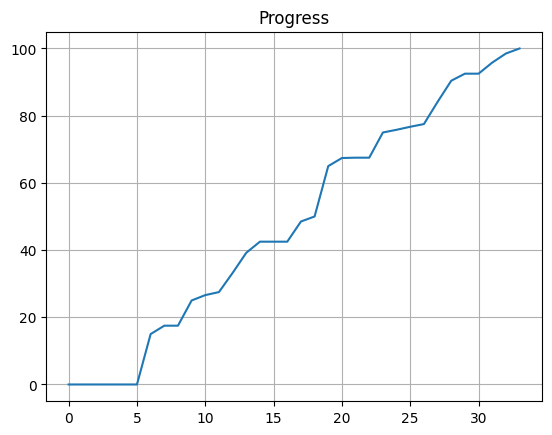

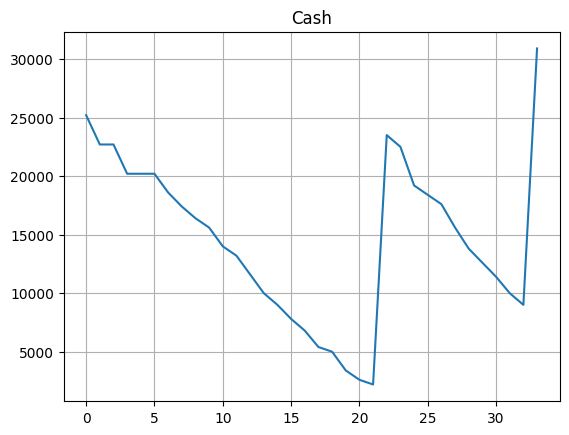

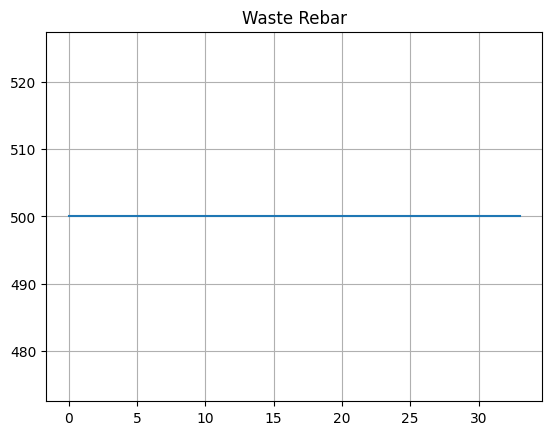

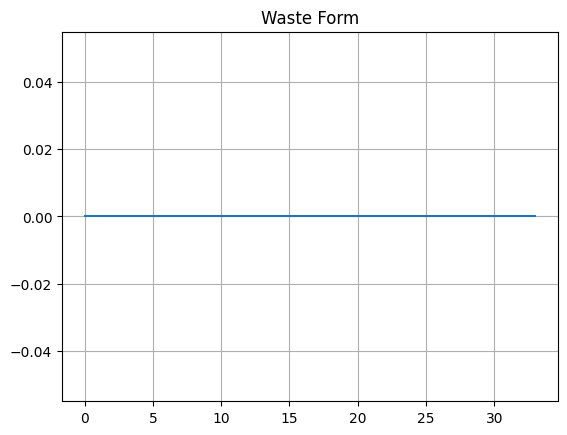

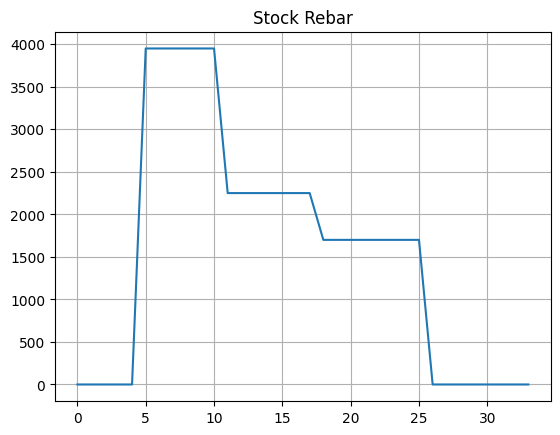

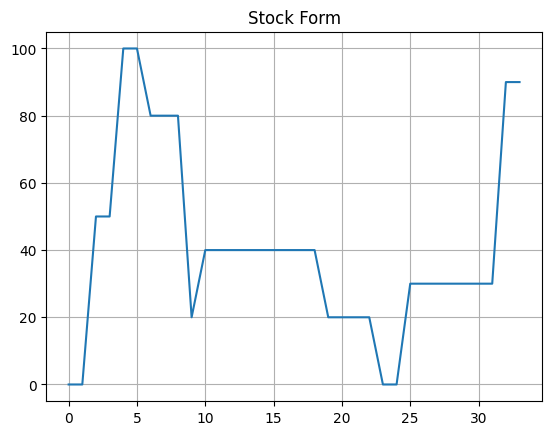

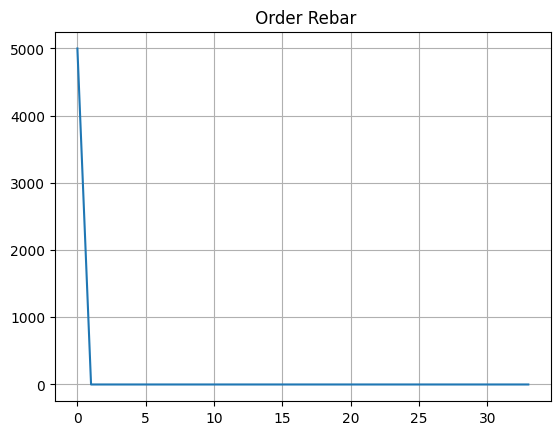

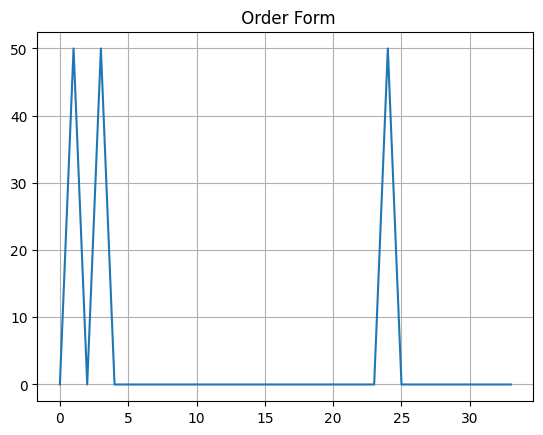

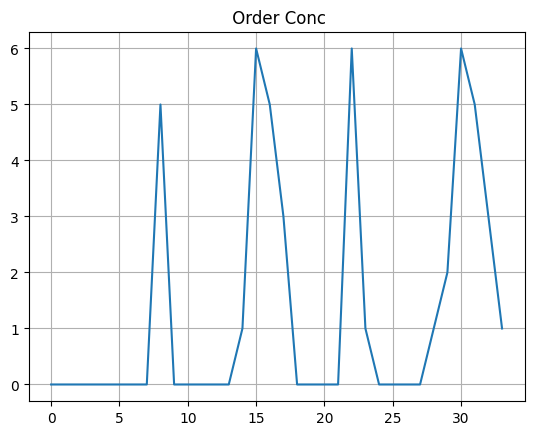

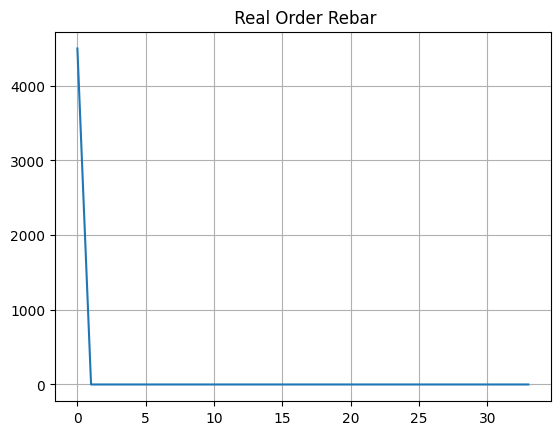

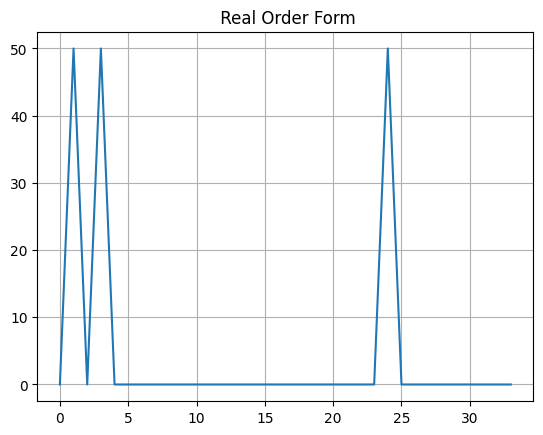

Order Rebar:   5000
Order Form:   150
Order Conc:   45
Waste Rebar:   500
Waste Form:   0
real Order Rebar:   4500
real Order Form:   150
real Waste Rebar =  0
real Waste Form =  -10.0
Cost Per Unit =    411.0


In [10]:
plt.plot(progress)
plt.title('Progress')
plt.grid(True)
plt.show()

plt.plot(cash)
plt.title('Cash')
plt.grid(True)
plt.show()

plt.plot(wasteRebar)
plt.title('Waste Rebar')
plt.grid(True)
plt.show()

plt.plot(wasteForm)
plt.title('Waste Form')
plt.grid(True)
plt.show()


plt.plot(stockRebar)
plt.title('Stock Rebar')
plt.grid(True)
plt.show()


plt.plot(stockForm)
plt.title('Stock Form')
plt.grid(True)
plt.show()



plt.plot(OrderRebar)
plt.title(' Order Rebar')
plt.grid(True)
plt.show()




plt.plot(OrderForm)
plt.title(' Order Form')
plt.grid(True)
plt.show()




plt.plot(OrderConc)
plt.title(' Order Conc')
plt.grid(True)
plt.show()



plt.plot(RealOrderRebar)
plt.title(' Real Order Rebar')
plt.grid(True)
plt.show()


plt.plot(RealOrderForm)
plt.title(' Real Order Form')
plt.grid(True)
plt.show()


print("Order Rebar:  ",sum(OrderRebar))
print("Order Form:  ",sum(OrderForm))
print("Order Conc:  ",sum(OrderConc))
print("Waste Rebar:  ",wasteRebar[-1])
print("Waste Form:  ",wasteForm[-1])
print("real Order Rebar:  ", sum(RealOrderRebar))
print("real Order Form:  ", sum(RealOrderForm))
print("real Waste Rebar = ", sum(RealOrderRebar) - myenv.areaZone*myenv.numZone*myenv.numFloor*45)
print("real Waste Form = ", sum(RealOrderForm) - myenv.areaZone*myenv.numZone*myenv.numFloor*1.6)
print("Cost Per Unit =   ", (myenv.cashStart - cash[-1] + myenv.numFloor*myenv.payPerUnit*(myenv.areaZone*myenv.numZone))/(myenv.areaZone*myenv.numZone*myenv.numFloor))


In [11]:
import csv
import os

# --- Define the export path ---
output_path = os.path.join(os.getcwd(), "Progress_Cash.csv")

# --- Dump progress and cash lists to CSV ---
with open(output_path, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Step", "Progress(%)", "CashInHand"])  # header row
    for i, (p, c) in enumerate(zip(progress, cash)):
        writer.writerow([i, p, c])

print(f"✅ Data successfully saved to: {output_path}")

✅ Data successfully saved to: d:\PhD\Thesis_2\4_Paper\3_Experiments\Exp1\Exp1A\RL\Python3\Progress_Cash.csv
